In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.9 MB/s eta 0:00:00


In [ ]:
!pip install albumentations

In [ ]:
import kagglehub
import os
# import zipfile
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import train_test_split
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import WeightedRandomSampler
import seaborn as sns
import random
from torch.cuda.amp import GradScaler, autocast

In [ ]:
TRAINING_CONFIG = {
    'batch_size_train': 16,
    'batch_size_val': 16,
    'batch_size_test': 8,
    'num_workers_train': 4,
    'num_workers_val': 4,
    'num_workers_test': 2,
    'num_epochs': 80,
    'patience': 15,
    'learning_rate': 3e-4,
    'weight_decay': 1e-5,
    'threshold': 0.5
}

In [ ]:
def denormalize(tensor, mean, std):
    mean = torch.tensor(mean).view(-1, 1, 1)
    std = torch.tensor(std).view(-1, 1, 1)
    return tensor * std + mean

In [ ]:
"""
zip_path = '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/open-bio-2024-final-project.zip'
extract_path = '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
"""

"\nzip_path = '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/open-bio-2024-final-project.zip'\nextract_path = '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/'\n\nwith zipfile.ZipFile(zip_path, 'r') as zip_ref:\n    zip_ref.extractall(extract_path)\n"

In [ ]:
train_fold = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/train/data/train.csv")
print(f"Loaded training data with {len(train_fold)} samples")

Loaded training data with 1744 samples


In [ ]:
train_fold.head()

,id,organ,data_source,img_height,img_width,pixel_size,tissue_thickness,age,sex,image_path,mask_path,slice_id
0,10274,prostate,HPA,512,512,0.4,4,76.0,Male,data/train/10274_0003.png,data/masks/10274_0003.png,10274_0003
1,10274,prostate,HPA,512,512,0.4,4,76.0,Male,data/train/10274_0001.png,data/masks/10274_0001.png,10274_0001
2,10274,prostate,HPA,512,512,0.4,4,76.0,Male,data/train/10274_0004.png,data/masks/10274_0004.png,10274_0004
3,10274,prostate,HPA,512,512,0.4,4,76.0,Male,data/train/10274_0000.png,data/masks/10274_0000.png,10274_0000
4,10274,prostate,HPA,512,512,0.4,4,76.0,Male,data/train/10274_0006.png,data/masks/10274_0006.png,10274_0006


In [ ]:
train_fold[['image_path', 'mask_path']].head()

,image_path,mask_path
0,data/train/10274_0003.png,data/masks/10274_0003.png
1,data/train/10274_0001.png,data/masks/10274_0001.png
2,data/train/10274_0004.png,data/masks/10274_0004.png
3,data/train/10274_0000.png,data/masks/10274_0000.png
4,data/train/10274_0006.png,data/masks/10274_0006.png


In [ ]:
train_fold['image_path'] = train_fold['image_path'].str.replace('data/train/', '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/train/data/train/')
train_fold['mask_path'] = train_fold['mask_path'].str.replace('data/masks/', '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/train/data/masks/')


In [ ]:
train_fold.head()

,id,organ,data_source,img_height,img_width,pixel_size,tissue_thickness,age,sex,image_path,mask_path,slice_id
0,10274,prostate,HPA,512,512,0.4,4,76.0,Male,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,10274_0003
1,10274,prostate,HPA,512,512,0.4,4,76.0,Male,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,10274_0001
2,10274,prostate,HPA,512,512,0.4,4,76.0,Male,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,10274_0004
3,10274,prostate,HPA,512,512,0.4,4,76.0,Male,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,10274_0000
4,10274,prostate,HPA,512,512,0.4,4,76.0,Male,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,10274_0006


In [ ]:
print(os.path.exists(train_fold.loc[0, 'image_path']))
print(os.path.exists(train_fold.loc[0, 'mask_path']))

True
True


In [ ]:
train_df, val_df = train_test_split(
    train_fold,
    test_size=0.1,
    random_state=42,
    shuffle=True,
    stratify=train_fold["organ"]
)
print(f"Training set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")

Training set size: 1569
Validation set size: 175


In [ ]:
len(set(train_df['image_path']) & set(val_df['image_path']))

0

<Axes: xlabel='organ', ylabel='count'>

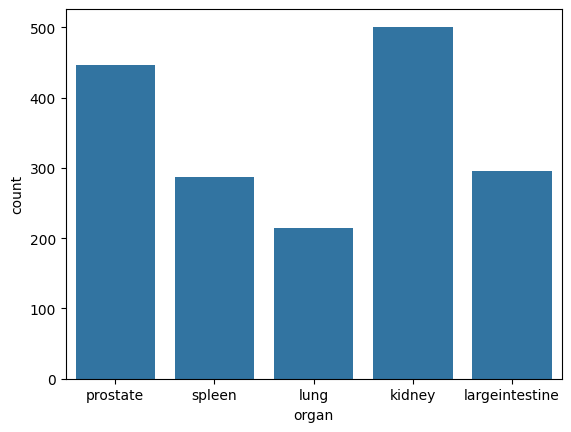

In [ ]:
sns.countplot(data=train_fold, x='organ')

In [ ]:
# Compute IoU (Jaccard) between predictions and masks
def compute_iou(preds, masks, threshold=TRAINING_CONFIG['threshold']):
    preds = (preds > threshold).float()
    intersection = (preds * masks).sum(dim=(1, 2, 3))
    union = ((preds + masks) >= 1).float().sum(dim=(1, 2, 3))
    iou = (intersection + 1e-6) / (union + 1e-6)
    return iou.mean().item()

In [ ]:
# Evaluate model and return average IoU
def evaluate_model(model, dataloader, device, threshold=TRAINING_CONFIG['threshold']):
    model.eval()
    iou_scores = []

    with torch.inference_mode():
        for batch in tqdm(dataloader, desc="Evaluating"):
            images = batch[0].to(device)
            masks = batch[1].to(device)

            with torch.amp.autocast(device_type='cuda' if device.type == 'cuda' else 'cpu'):
                outputs = model(images)
                preds = torch.sigmoid(outputs)

            iou = compute_iou(preds, masks, threshold)
            iou_scores.append(iou)

    return np.mean(iou_scores)

In [ ]:
class SegmentationDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "image_path"]
        mask_path = self.df.loc[idx, "mask_path"]

        # Load images
        image = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Apply Albumentations transform
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]
            mask = (mask > 0).float()  # Mask binarization

        mask = mask.unsqueeze(0)
        return image, mask

In [ ]:
class SimpleCombinedLoss(nn.Module):
    def __init__(self):
        super(SimpleCombinedLoss, self).__init__()
        self.dice_loss = smp.losses.DiceLoss(mode='binary')
        # self.bce_loss = smp.losses.SoftBCEWithLogitsLoss()
        self.bce_loss = smp.losses.SoftBCEWithLogitsLoss(pos_weight=torch.tensor([10.0]).to(device))

    def forward(self, outputs, targets):
        dice = self.dice_loss(outputs, targets)
        bce = self.bce_loss(outputs, targets)
        return 0.5 * dice + 0.5 * bce

In [ ]:
# Mean: [0.7756168  0.75037868 0.76858318]
# Std: [0.22779241 0.2376828  0.23061448]

In [ ]:
# Train transforms
train_transform = A.Compose([
    A.HorizontalFlip(p=0.2),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.2),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=5,
                       p=0.2, interpolation=1, border_mode=0),
    A.GaussianBlur(blur_limit=3, p=0.05),
    # A.Normalize(mean=(0.7756168, 0.75037868, 0.76858318), std=(0.22779241, 0.2376828, 0.23061448)),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Validation transforms
val_transform = A.Compose([
    # A.Normalize(mean=(0.7756168, 0.75037868, 0.76858318), std=(0.22779241, 0.2376828, 0.23061448)),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Test transforms
test_transform = A.Compose([
    # A.Normalize(mean=(0.7756168, 0.75037868, 0.76858318), std=(0.22779241, 0.2376828, 0.23061448)),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
train_dataset = SegmentationDataset(dataframe=train_df, transform=train_transform)
val_dataset = SegmentationDataset(dataframe=val_df, transform=val_transform)

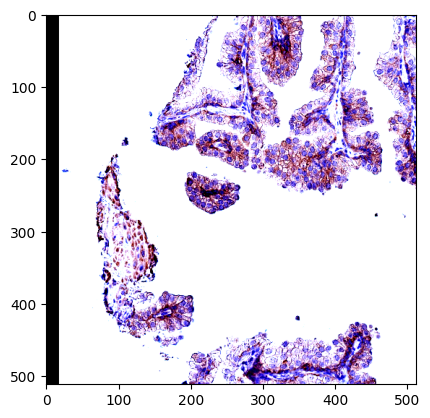

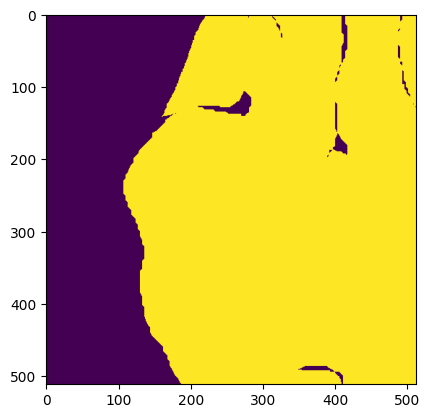

In [ ]:
# Example for visualization
img, mask = train_dataset[0]
img_np = img.permute(1, 2, 0).cpu().numpy()
mask_np = mask.squeeze().cpu().numpy()

plt.imshow(img_np)
plt.show()

plt.imshow(mask_np)
plt.show()

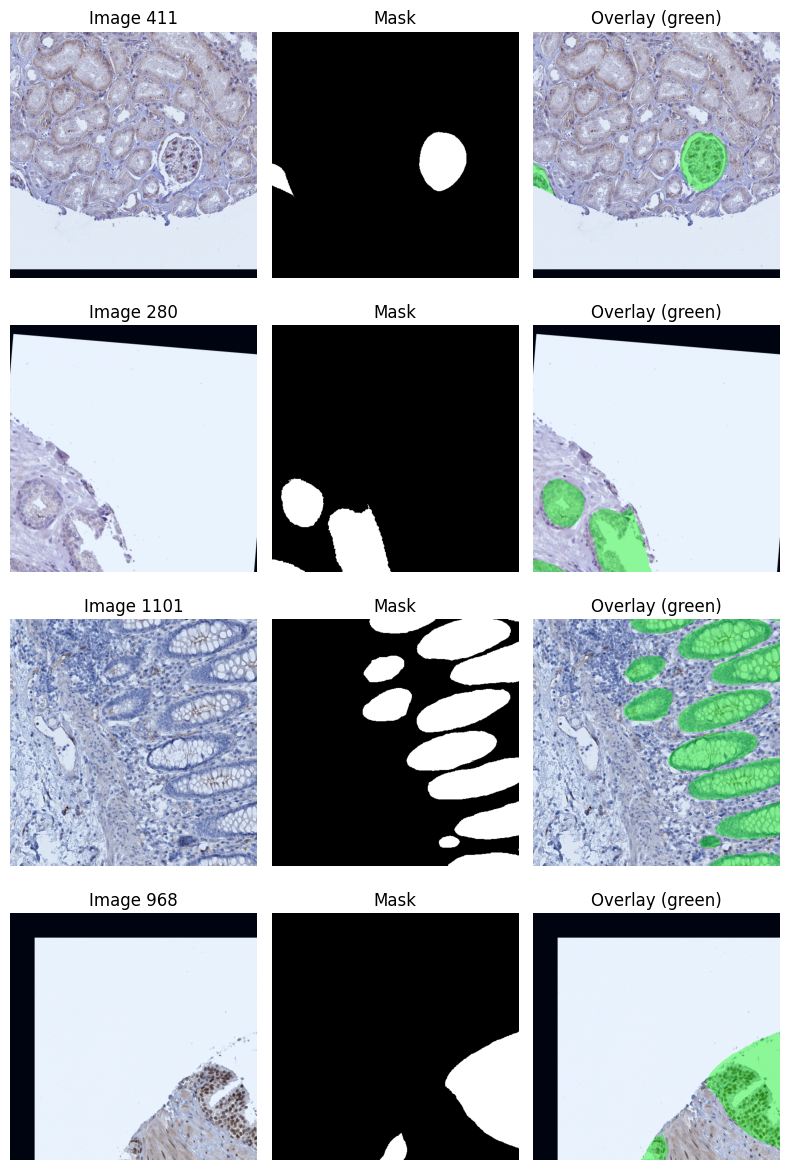

In [ ]:
n = 4
indices = random.sample(range(len(train_dataset)), n)

plt.figure(figsize=(8, n * 3))

for i, idx in enumerate(indices):
    img, mask = train_dataset[idx]

    img_np = img.permute(1, 2, 0).cpu().numpy()
    mask_np = mask.squeeze().cpu().numpy()

    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)

    overlay = img_np.copy()

    color = np.array([0.0, 1.0, 0.0])
    alpha = 0.4
    mask_bool = mask_np > 0

    overlay[mask_bool] = (
        (1 - alpha) * overlay[mask_bool] + alpha * color
    )

    plt.subplot(n, 3, 3 * i + 1)
    plt.imshow(img_np)
    plt.title(f"Image {idx}")
    plt.axis("off")

    plt.subplot(n, 3, 3 * i + 2)
    plt.imshow(mask_np, cmap="gray")
    plt.title("Mask")
    plt.axis("off")

    plt.subplot(n, 3, 3 * i + 3)
    plt.imshow(overlay)
    plt.title("Overlay (green)")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
mean_pos = train_dataset[0][1].mean().item()
print("Average mask fill:", mean_pos)

Average mask fill: 0.6943435668945312


In [ ]:
train_dataset[0]

(tensor([[[-2.1179, -2.1179, -2.1179,  ...,  0.5364,  0.6563,  0.7762],
          [-2.1179, -2.1179, -2.1179,  ...,  0.6221,  0.6049,  0.6563],
          [-2.1179, -2.1179, -2.1179,  ..., -0.1486,  0.0056,  0.4337],
          ...,
          [-2.1179, -2.1179, -2.1179,  ...,  1.4098,  1.4098,  1.4269],
          [-2.1179, -2.1179, -2.1179,  ...,  1.3927,  1.4098,  1.3927],
          [-2.1179, -2.1179, -2.1179,  ...,  1.3927,  1.4098,  1.4098]],
 
         [[-2.0357, -2.0357, -2.0357,  ...,  0.6078,  0.7304,  0.7654],
          [-2.0357, -2.0357, -2.0357,  ...,  0.5203,  0.5378,  0.6429],
          [-2.0357, -2.0357, -2.0357,  ..., -0.2500, -0.0574,  0.4503],
          ...,
          [-2.0357, -2.0357, -2.0357,  ...,  1.5532,  1.5532,  1.5707],
          [-2.0357, -2.0357, -2.0357,  ...,  1.5532,  1.5532,  1.5357],
          [-2.0357, -2.0357, -2.0357,  ...,  1.5532,  1.5532,  1.5707]],
 
         [[-1.8044, -1.8044, -1.8044,  ...,  1.2457,  1.3502,  1.3851],
          [-1.8044, -1.8044,

In [ ]:
train_dataset[0][0].shape

torch.Size([3, 512, 512])

In [ ]:
counts = train_df["organ"].value_counts()
sample_weights = 1.0 / train_df["organ"].map(counts)

sampler = WeightedRandomSampler(
    weights=sample_weights.values,
    num_samples=len(sample_weights),
    replacement=True
)

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=TRAINING_CONFIG['batch_size_train'],
    sampler=sampler,
    shuffle=False,
    num_workers=TRAINING_CONFIG['num_workers_train'],
    pin_memory=True,
    drop_last=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=TRAINING_CONFIG['batch_size_val'],
    shuffle=False,
    num_workers=TRAINING_CONFIG['num_workers_val'],
    pin_memory=True,
    drop_last=True
)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:
for x, y in train_loader:
    print("Mask dtype:", y.dtype)
    break

Mask dtype: torch.float32


In [ ]:
"""
model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights="imagenet",
    decoder_use_batchnorm=True,
    decoder_attention_type="scse",
    in_channels=3,
    classes=1,
)
"""

'\nmodel = smp.Unet(\n    encoder_name="resnet18",\n    encoder_weights="imagenet",\n    decoder_use_batchnorm=True,\n    decoder_attention_type="scse",\n    in_channels=3,\n    classes=1,\n)\n'

In [ ]:
model = smp.DeepLabV3Plus(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    classes=1,
    activation=None
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
print(f"Using device: {device}")

Using device: cuda


In [ ]:
# Optimizer and scheduler
optimizer = torch.optim.AdamW(model.parameters(), lr=TRAINING_CONFIG['learning_rate'], weight_decay=TRAINING_CONFIG['weight_decay'])
scheduler = ReduceLROnPlateau(optimizer, patience=2, factor=0.5)
criterion = SimpleCombinedLoss()

In [ ]:
"""
Check batch dimensions, expect:
Batch 0 - Image shape: torch.Size([16, 3, 512, 512]),
Mask shape: torch.Size([16, 1, 512, 512])
"""

for batch_idx, data in enumerate(train_loader):
    x, y = data
    print(f"Batch {batch_idx} - Image shape: {x.shape}, Mask shape: {y.shape}")
    break

Batch 0 - Image shape: torch.Size([16, 3, 512, 512]), Mask shape: torch.Size([16, 1, 512, 512])


In [ ]:
scaler = GradScaler(enabled=(device.type == 'cuda'))

/tmp/ipython-input-2777085285.py:1: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=(device.type == 'cuda'))


In [ ]:
num_epochs = TRAINING_CONFIG['num_epochs']
patience = TRAINING_CONFIG['patience']
epochs_without_improvement = 0
best_val_iou = 0
best_model_path = "/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/best_model.pth"

train_ious = []
val_ious = []

for epoch in range(num_epochs):
    model.train()
    train_loss_history = []

    print(f"Starting epoch {epoch+1}/{num_epochs}")

    for batch_idx, data in tqdm(enumerate(train_loader), total=len(train_loader)):
    # for batch_idx, data in tqdm(enumerate(train_loader), total=5):

        x, y = data[0].to(device).float(), data[1].to(device).float()

        optimizer.zero_grad()

        with autocast(enabled=(device.type == 'cuda')):
            ypred = model(x)
            loss = criterion(ypred, y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_history.append(loss.item())

    # Update learning rate
    avg_train_loss = np.mean(train_loss_history)
    scheduler.step(avg_train_loss)

    print(f"EPOCH {epoch+1}/{num_epochs}, Train Loss: {avg_train_loss:.4f}, LR: {optimizer.param_groups[0]['lr']:.6f}")

    if epoch % 2 == 0:
        train_iou = evaluate_model(model, train_loader, device, TRAINING_CONFIG['threshold'])
    else:
        train_iou = train_ious[-1] if train_ious else 0.0

    val_iou = evaluate_model(model, val_loader, device, TRAINING_CONFIG['threshold'])
    print(f"[Epoch {epoch+1}] Train IoU: {train_iou:.4f}, Val IoU: {val_iou:.4f}")

    train_ious.append(train_iou)
    val_ious.append(val_iou)

    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save(model.state_dict(), best_model_path)
        print(f"Saved new best model with Val IoU: {val_iou:.4f}")
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        print(f"No improvement. Patience: {epochs_without_improvement}/{patience}")

        if epochs_without_improvement >= patience:
            print("Early stopping triggered")
            break

Starting epoch 1/80


  0%|          | 0/98 [00:00<?, ?it/s]/tmp/ipython-input-2374760103.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(device.type == 'cuda')):
100%|██████████| 98/98 [06:18<00:00,  3.86s/it]


EPOCH 1/80, Train Loss: 0.6534, LR: 0.000300


Evaluating: 100%|██████████| 10/10 [01:24<00:00,  8.50s/it]


[Epoch 1] Train IoU: 0.3937, Val IoU: 0.4266
Saved new best model with Val IoU: 0.4266
Starting epoch 2/80


...

[Epoch 28] Train IoU: 0.7413, Val IoU: 0.6169
No improvement. Patience: 11/15
Starting epoch 29/80



100%|██████████| 98/98 [00:50<00:00,  1.96it/s]


EPOCH 29/80, Train Loss: 0.1624, LR: 0.000300


Evaluating:  69%|██████▉   | 68/98 [19:25<08:34, 17.15s/it]


KeyboardInterrupt: 

In [ ]:
# Check if weights change
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, param.data.mean().item(), param.grad.abs().mean().item())
        break


encoder.conv1.weight -0.0006586922099813819 0.0015702469972893596


In [ ]:
print(f"Training completed. Best validation IoU: {best_val_iou:.4f}")

Training completed. Best validation IoU: 0.6334


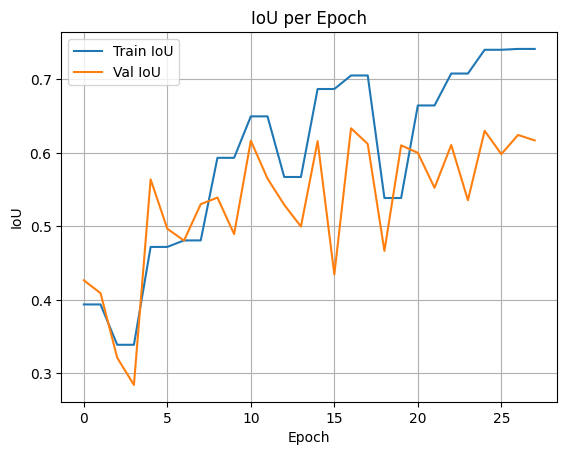

In [ ]:
# Plot training curves
plt.plot(train_ious, label="Train IoU")
plt.plot(val_ious, label="Val IoU")
plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.legend()
plt.grid()
plt.title("IoU per Epoch")
plt.show()

In [ ]:
with torch.amp.autocast(device_type='cuda' if device.type == 'cuda' else 'cpu'):
    with torch.inference_mode():
        pred = model(x.float().to(device))

In [ ]:
pred = pred.detach().cpu().numpy()

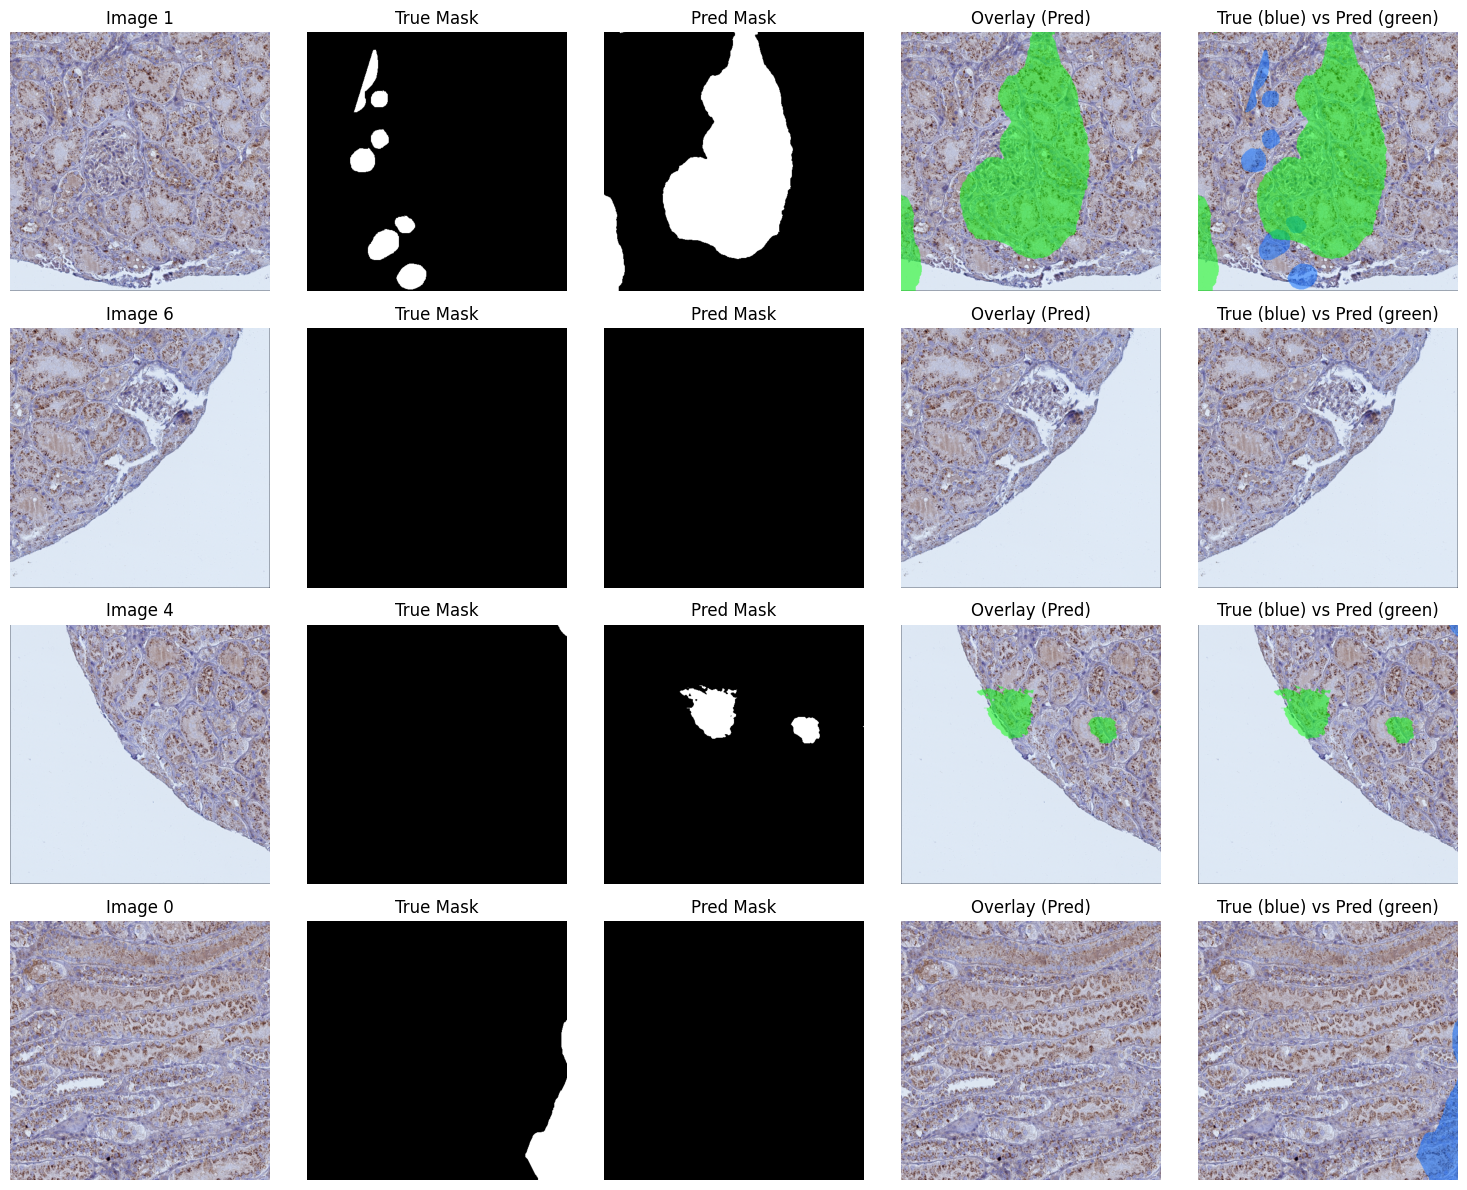

In [ ]:
def show_pred_overlays(
    x, y, pred, threshold=0.5, n=4, indices=None, title_prefix=""
):

    if isinstance(x, np.ndarray): x = torch.tensor(x)
    if isinstance(y, np.ndarray): y = torch.tensor(y)
    if isinstance(pred, np.ndarray): pred = torch.tensor(pred)

    x = x.detach().cpu()
    y = y.detach().cpu()
    pred = pred.detach().cpu()

    if pred.dtype.is_floating_point:
        pred_prob = torch.sigmoid(pred)
    else:
        pred_prob = pred

    pred_mask = (pred_prob > threshold).float()
    pred_mask_np = pred_mask.squeeze(1).numpy()  # (B, H, W)
    true_mask_np = y.squeeze(1).numpy()          # (B, H, W)

    B = x.size(0)
    if indices is None:
        indices = random.sample(range(B), min(n, B))
    rows = len(indices)

    plt.figure(figsize=(15, rows * 3))

    for r, i in enumerate(indices):
        img_np = x[i].permute(1, 2, 0).numpy()
        img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)

        m_true = true_mask_np[i].astype(bool)
        m_pred = pred_mask_np[i].astype(bool)

        overlay_pred = img_np.copy()
        color_pred = np.array([0.0, 1.0, 0.0])
        alpha = 0.5
        overlay_pred[m_pred] = (1 - alpha) * overlay_pred[m_pred] + alpha * color_pred

        overlay_comp = img_np.copy()
        color_true = np.array([0.0, 0.4, 1.0])
        color_pred = np.array([0.0, 1.0, 0.0])
        alpha_t, alpha_p = 0.5, 0.5
        overlay_comp[m_true] = (1 - alpha_t) * overlay_comp[m_true] + alpha_t * color_true
        overlay_comp[m_pred] = (1 - alpha_p) * overlay_comp[m_pred] + alpha_p * color_pred

        col = 5
        ax = plt.subplot(rows, col, col * r + 1)
        ax.imshow(img_np)
        ax.set_title(f"{title_prefix}Image {i}")
        ax.axis("off")

        ax = plt.subplot(rows, col, col * r + 2)
        ax.imshow(m_true, cmap="gray")
        ax.set_title("True Mask")
        ax.axis("off")

        ax = plt.subplot(rows, col, col * r + 3)
        ax.imshow(m_pred, cmap="gray")
        ax.set_title("Pred Mask")
        ax.axis("off")

        ax = plt.subplot(rows, col, col * r + 4)
        ax.imshow(overlay_pred)
        ax.set_title("Overlay (Pred)")
        ax.axis("off")

        ax = plt.subplot(rows, col, col * r + 5)
        ax.imshow(overlay_comp)
        ax.set_title("True (blue) vs Pred (green)")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_pred_overlays(x, y, pred, threshold=TRAINING_CONFIG['threshold'], n=4)

Min/max Predictions:  -14.398367 -2.293701


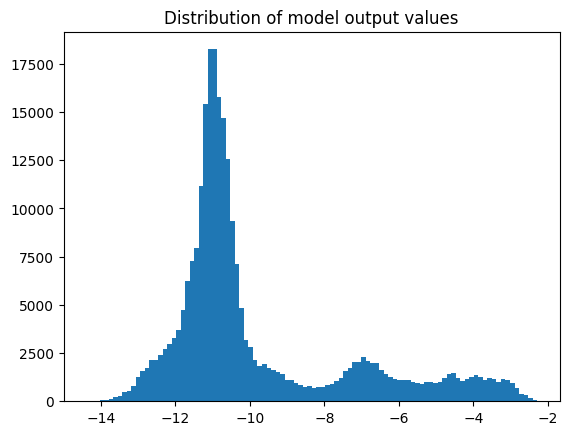

In [ ]:
# Preparing a batch
x, y = next(iter(val_loader))
x = x.to(device)
with torch.no_grad():
    out = model(x)

# Check values of output tensor
out_cpu = out[0].detach().cpu().squeeze().numpy()

# Show range of values on histogram
print("Min/max Predictions: ", out_cpu.min(), out_cpu.max())
plt.hist(out_cpu.flatten(), bins=100)
plt.title("Distribution of model output values")
plt.show()

In [ ]:
class SegmentationDatasetSubmit(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "image_path"]
        slice_id = self.df.loc[idx, "slice_id"]

        image = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image=image)["image"]

        return image, slice_id

In [ ]:
test_fold = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/test/test.csv")

In [ ]:
test_fold.head()

,id,organ,data_source,img_height,img_width,pixel_size,tissue_thickness,age,sex,image_path,slice_id
0,10044,prostate,HPA,512,512,0.4,4,37.0,Male,test/10044_0004.png,10044_0004
1,10044,prostate,HPA,512,512,0.4,4,37.0,Male,test/10044_0007.png,10044_0007
2,10044,prostate,HPA,512,512,0.4,4,37.0,Male,test/10044_0001.png,10044_0001
3,10044,prostate,HPA,512,512,0.4,4,37.0,Male,test/10044_0002.png,10044_0002
4,10044,prostate,HPA,512,512,0.4,4,37.0,Male,test/10044_0003.png,10044_0003


In [ ]:
test_fold['image_path'] = test_fold['image_path'].str.replace('test/', '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/test/test/')

In [ ]:
test_dataset = SegmentationDatasetSubmit(dataframe=test_fold, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=TRAINING_CONFIG['batch_size_test'], shuffle=False, num_workers=TRAINING_CONFIG['num_workers_test'])

In [ ]:
def rle_encode(mask: np.ndarray) -> str:
    """
    Convert a 2‑D binary mask to the Kaggle run‑length encoding format.

    Parameters
    ----------
    mask : np.ndarray
        2‑D array of type bool, int, or uint8 where non‑zero pixels are foreground.

    Returns
    -------
    str
        Space‑separated "start length start length ..." string.
        An empty string is returned when the mask is empty.

    Notes
    -----
    • Pixels are enumerated column‑wise with 1‑based indexing.
    • The function tolerates non‑boolean dtypes by thresholding `>0`.
    """
    if mask.ndim != 2:
        raise ValueError("Input mask must be 2‑D")

    # Convert to 1‑D column‑major vector of 0 and 1
    pixels = (mask > 0).T.flatten()        # transpose then flatten (C order) == flatten(order="F")

    if pixels.sum() == 0:
        return "0"                          # empty mask

    # Pad zeros at both ends to catch runs that start or end at image borders
    padded = np.concatenate([[0], pixels, [0]])
    changes = np.where(padded[1:] != padded[:-1])[0] + 1   # indices where value flips

    runs = changes[1::2] - changes[0::2]                   # run lengths
    starts = changes[0::2]                                 # 1‑based already

    rle = np.column_stack((starts, runs)).flatten()
    return " ".join(str(x) for x in rle)

In [ ]:
submission = {"id": [], "rle_mask": []}

In [ ]:
# Load best model
model.load_state_dict(torch.load(best_model_path, map_location=device))

<All keys matched successfully>

In [ ]:
print("Starting inference on test set...")
model.eval()
for data in tqdm(test_loader):
    x = data[0].to(device).float()
    slice_id = data[1]

    with torch.inference_mode():
        with torch.amp.autocast(device_type='cuda' if device.type == 'cuda' else 'cpu'):
            ypred = torch.sigmoid(model(x))

    for i in range(ypred.shape[0]):
        pred_mask = (ypred[i, 0] > TRAINING_CONFIG['threshold']).detach().cpu().numpy()
        rle_mask = rle_encode(pred_mask)
        submission["id"].append(slice_id[i])
        submission["rle_mask"].append(rle_mask)

Starting inference on test set...


100%|██████████| 144/144 [08:10<00:00,  3.41s/it]


In [ ]:
pd.DataFrame(submission)

,id,rle_mask
0,10044_0004,1 417 469 461 982 460 1495 458 2009 456 2522 4...
1,10044_0007,1 194 513 194 1025 194 1537 194 2049 194 2561 ...
2,10044_0001,202 265 480 33 713 266 991 34 1225 266 1502 35...
3,10044_0002,216 25 248 178 728 26 760 183 1240 26 1273 184...
4,10044_0003,74509 7 74527 7 75017 34 75517 52 76026 64 765...
...,...,...
1146,9769_0000,0
1147,9769_0002,0
1148,9769_0006,250167 1 250173 7 250674 21 250699 2 251183 36...
1149,9769_0005,0


In [ ]:
pd.DataFrame(submission).to_csv("submission_besedina_unet.csv", index=False)

In [ ]:
print("Saved submission file")

Saved submission file


In [ ]:
import json

kaggle_token = {
    "username": "tomascitech",
    "key": "c9db55b121227f1757d0cb7b9ee3167b"
}

os.makedirs("/root/.kaggle", exist_ok=True)
with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(kaggle_token, f)
os.chmod("/root/.kaggle/kaggle.json", 0o600)

# Submit to Kaggle using shell command for Colab
!kaggle competitions submit -c open-bio-spring-2025-final-project -f submission_besedina.csv -m "DeepLabV3+"

[Errno 2] No such file or directory: 'submission_besedina.csv'


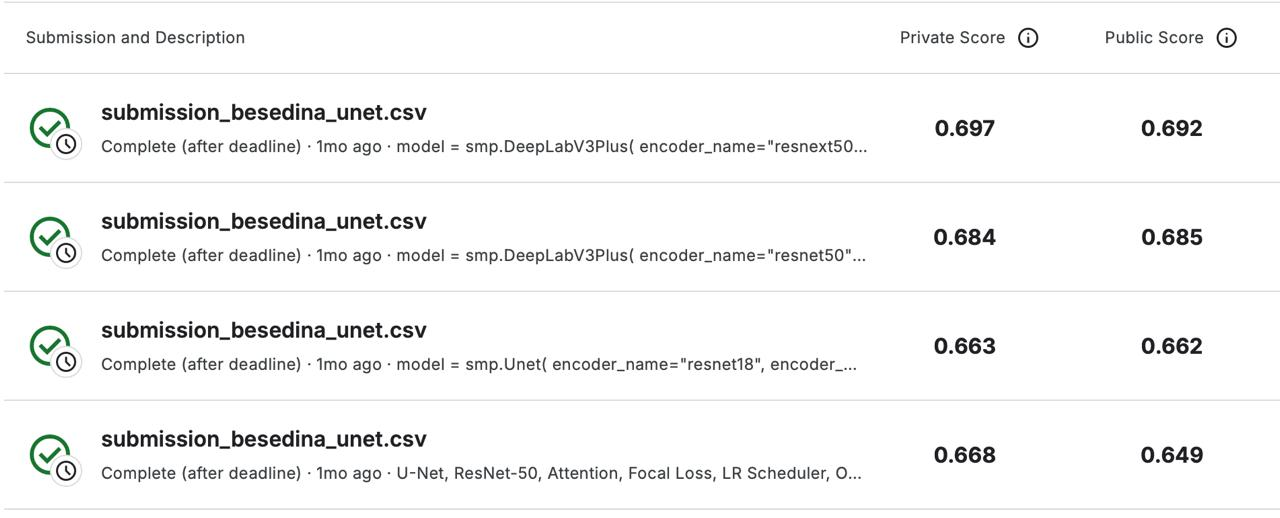